In [174]:
import numpy as np
import pandas as pd
import matplotlib.pylab as plt
%matplotlib inline

## Step 1

In [175]:
df = pd.read_csv('dataset.csv')
df.sample(5)

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
1640,90,2,True,True,True,Golestan,6.900000e+08,23000.00
633,100,2,True,True,True,Heravi,5.500000e+09,183333.33
2853,81,2,True,True,False,Valiasr,1.800000e+09,60000.00
2987,70,2,True,True,False,Punak,2.170000e+09,72333.33
30,90,2,False,True,False,Salsabil,1.500000e+09,50000.00


### وجود دارد یا خیر؟ (null) در این قسمت بررسی می کنیم توی دیتاست داده تکراری یا


In [176]:
print(f'total duplicated data : {df.duplicated().sum()}\ntoal null data : {df.isnull().sum()}')

total duplicated data : 208
toal null data : Area           0
Room           0
Parking        0
Warehouse      0
Elevator       0
Address       23
Price          0
Price(USD)     0
dtype: int64


In [177]:
df[df.duplicated(keep=False)].sort_values(by=['Area', 'Room'])

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
342,100,2,True,True,True,Gheitarieh,8.000000e+09,266666.67
797,100,2,True,True,True,Pardis,5.000000e+08,16666.67
1080,100,2,False,True,False,Tehransar,2.000000e+09,66666.67
1223,100,2,True,True,True,Pardis,5.000000e+08,16666.67
1521,100,2,False,True,False,Tehransar,2.000000e+09,66666.67
...,...,...,...,...,...,...,...,...
1932,98,2,True,True,True,Shahr-e-Ziba,3.220000e+09,107333.33
2408,98,2,True,True,True,Pardis,7.700000e+08,25666.67
2811,98,2,True,True,True,Si Metri Ji,1.950000e+09,65000.00
2857,98,2,True,True,True,Si Metri Ji,1.950000e+09,65000.00


<div dir="rtl" style="text-align: right;">

### از نظر تئوریک و منطقی دو یا سه خانه با مشخصات یکسان می توانند داده های یکسانی داشته باشند، پس برای این مورد دست به حذف مقادیر تکرای نمی زنیم

</div>

In [178]:
df[df['Address'].isna()].head()

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
43,60,2,True,True,True,NaN,2.650000e+09,88333.33
662,85,2,True,True,True,NaN,1.955000e+09,65166.67
706,117,2,True,True,True,NaN,6.500000e+09,216666.67
1108,77,2,True,True,False,NaN,2.020000e+09,67333.33
1109,71,1,True,True,True,NaN,2.300000e+09,76666.67


<div dir="rtl" style="text-align: right;">

### برای جلوگیری از خطاهای احتمالی، رکوردهایی که آدرس null دارند را حذف میکنیم
</div>

In [179]:
df.dropna(inplace=True)
df.isna().sum()

Area          0
Room          0
Parking       0
Warehouse     0
Elevator      0
Address       0
Price         0
Price(USD)    0
dtype: int64

* کد زیر بعد جلو رفتن چندین مرحله اضافه شده، جلوتر متوجه شدم که تایپ مساحت خانه از نوع آبجکت هستش

In [201]:
df['Area'] = df['Area'].astype(str)
df['Area'] = (
    df['Area']
    .str.replace(',', '', regex=False)
    .str.strip()
    .astype(float)
)
df['Area']

0        63.0
1        60.0
2        79.0
3        95.0
4       123.0
        ...  
3474     86.0
3475     83.0
3476     75.0
3477    105.0
3478     82.0
Name: Area, Length: 3456, dtype: float64

 ## Step 2
ساخت نمودارهای مختلف و بررسی روابط بین دیتاها

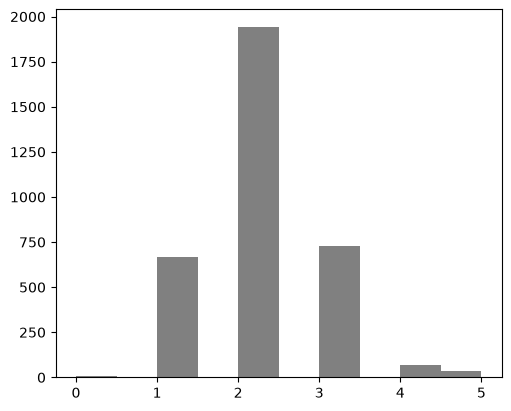

In [11]:
fig, axs = plt.subplots(figsize=(5, 4), layout='constrained')
axs.hist(df['Room'], color='gray');

بررسی تاثیر متراژ خانه بر ارزش خانه

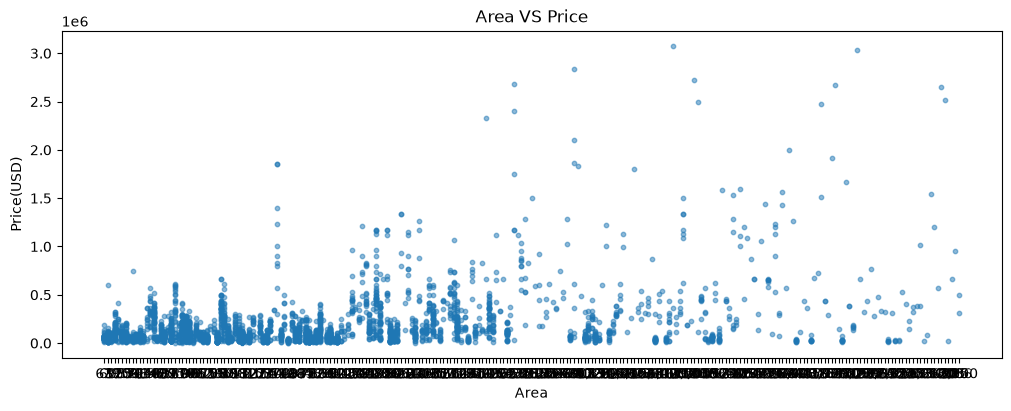

In [32]:
fig, axs = plt.subplots(figsize=(10, 4), layout='constrained')
axs.scatter(
    df['Area'],
    df['Price(USD)'],
    alpha=0.5,
    s=10
)
axs.set_title('Area VS Price')
axs.set_xlabel('Area')
axs.set_ylabel('Price(USD)')
plt.show()

## Step 3

### برای تقسیم بندی داده ها به داده های آموزش و تست می توانیم از متد تعریف شده استفاده کنیم
- این نکته قابل توجه می باشد که با استفاده از ساخت ماسک هم می شد این کار را انجام داد

In [67]:
df

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
0,63,1,True,True,True,Shahran,1.850000e+09,61666.67
1,60,1,True,True,True,Shahran,1.850000e+09,61666.67
2,79,2,True,True,True,Pardis,5.500000e+08,18333.33
3,95,2,True,True,True,Shahrake Qods,9.025000e+08,30083.33
4,123,2,True,True,True,Shahrake Gharb,7.000000e+09,233333.33
...,...,...,...,...,...,...,...,...
3474,86,2,True,True,True,Southern Janatabad,3.500000e+09,116666.67
3475,83,2,True,True,True,Niavaran,6.800000e+09,226666.67
3476,75,2,False,False,False,Parand,3.650000e+08,12166.67
3477,105,2,True,True,True,Dorous,5.600000e+09,186666.67


In [218]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X = df[['Room', 'Parking', 'Elevator']]
Y = df['Price(USD)']

x_train, x_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(x_train, y_train)
y_predict = model.predict(x_test)

In [219]:
model.score(x_test, y_test)

0.34370040125014345

### این پروژه همینجا تموم شد، چند سوال که ممکنه براتون به وجود اومده باشه
* من میتونستم برای مدل وقت بیشتری بزارم تا دقتش رو افزایش بدم، با بررسی روابط پارامتر های مختلف؛ اما ترجیحم به عنوان کسی که داره مهندس هوش مصنوعی میشه اینکه تا همینجا کافیه
* شاید براتون سوال بشه چرا متراژ خانه توی کد آخر برای پیش بینی قیمت استفاده نشده، چون وقتی استفاده شد دقت 